# 03 — Preprocess the economic data (GDP, SME, SAMA, licensing)

Turns the GASTAT and SAMA files into **market features per SSIC section and start quarter**, so that every
business gets the market numbers it could have known **before** it started.

**Reads:** `pipeline/00_raw/gastat`, `pipeline/00_raw/sama` (from `00_download`) and the cities in
`pipeline/02_businesses.parquet` (from `02`).
**Saves:** `pipeline/03_gdp_features.parquet`, `03_sme_features.parquet`, `03_sama_sector_features.parquet`,
`03_sama_city_features.parquet`, `03_city_to_sama.csv`, `03_licensing.parquet`, `03_ssic_sections.csv`.

### The leakage rule, and the delays
A business that starts in quarter **Q** may only use numbers that were **published** before Q:

| Source | Delay used | Why |
|---|---|---|
| GDP (quarterly) | `GDP_LAG = 2` quarters | GASTAT publishes a quarter about 2–3 months after it ends: in Nov 2026 the newest is 2026 Q2 |
| SME (yearly) | `SME_LAG = 2` years | The year Y survey is published in late Y+1: in 2026 the newest is 2024 |
| SAMA (weekly) | the 52 weeks before Q | SAMA publishes every week, a few days after it ends |

With these delays a training business sees exactly what a founder sees on the website today. **The delays are
a decision for the team:** change them in the next cell if needed.

**The notebooks, in order** (each one loads what the one before saved, so nothing is downloaded or read from Excel twice):

| # | Notebook | Saves (in `Darb DataSets/pipeline`) |
|---|---|---|
| 00 | `00_download` | `00_raw/`: an exact copy of every raw file, as fast parquet |
| 01 | `01_eda_raw` | `01_quarter_quality.csv`: how complete each MC quarter is |
| 02 | `02_preprocess_businesses` | `02_businesses.parquet`: one row per business, with its label |
| 03 | `03_preprocess_economic` | `03_*.parquet`: GDP, SME, SAMA and licensing features |
| 04 | `04_eda_clean` | nothing (looks only) |
| 05 | `05_features` | `05_model_table.parquet`: the model's inputs and the time split |
| 06 | `06_baseline` | `06_baseline_results.csv` |
| 07 | `07_tuning` | `07_best_params.json`, `07_tuning_results.csv` |
| 08 | `08_final_training` | `models/`: the final model and its report |

**Rules:** raw files are never changed · nothing is dropped (problems get a flag) · data never goes into Git ·
clear all outputs before committing.

### Setup
Finds the data folder. **Locally** it is `~/darb-data` (or the folder in the `DARB_DATA` setting), a copy of the
team's Drive folder **Darb DataSets**. **On Colab** it is Darb DataSets itself: add a shortcut to it in your My
Drive first, and upload the files of `ml/src` to `/content`.

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = Path('/content/drive/MyDrive/Darb DataSets')   # a shortcut to the team folder in your My Drive
    SRC_DIR = Path('/content')                                # upload the files of ml/src here
    !pip install -q python-calamine lightgbm xgboost shap
else:
    DATA_DIR = Path(os.environ.get('DARB_DATA', Path.home() / 'darb-data'))   # local copy of Darb DataSets
    SRC_DIR = Path.cwd().parent / 'src'

PIPE = DATA_DIR / 'pipeline'          # every notebook saves its results here (never in Git)
PIPE.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SRC_DIR))


def need(path, notebook):
    """Stops with a clear message when a file from an earlier notebook is missing."""
    if not Path(path).exists():
        raise FileNotFoundError(f'{Path(path).name} not found: run {notebook} first.')
    return Path(path)


print('Colab' if IN_COLAB else 'Local', '| data:', DATA_DIR, '| results:', PIPE)

Local | data: /Users/halaalsabbar/darb-data | results: /Users/halaalsabbar/darb-data/pipeline


In [2]:
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAW = need(PIPE / '00_raw', '00_download')
GDP_LAG = 2       # quarters
SME_LAG = 2       # years
FIRST_START, LAST_START = '2023Q1', '2027Q1'          # start quarters to build: training cohorts up to the website's next quarter
SECTIONS = list('ABCDEFGHIJKLMNOPQRSTU')
pd.set_option('display.width', 200)
warnings.simplefilter('ignore', DeprecationWarning)

def qnum(label):
    return int(label[:4]) * 4 + int(label[-1]) - 1

def qlabel(n):
    return f'{n // 4}Q{n % 4 + 1}'

START_QUARTERS = [qlabel(n) for n in range(qnum(FIRST_START), qnum(LAST_START) + 1)]
print('Start quarters:', START_QUARTERS[0], 'to', START_QUARTERS[-1])

Start quarters: 2023Q1 to 2027Q1


## Part A — GDP by economic activity (GASTAT, quarterly)

### A1 — Clean
Values to numbers, quarters to numbers (`20101` = 2010 Q1). The same activity and quarter must have one value.

In [3]:
gdp = pd.read_parquet(RAW / 'gastat' / 'gastat_gdp_2026-10-21T09_14_09.657Z.csv.parquet')
gdp = gdp.rename(columns={'Quarter ID': 'quarter_id', 'Quarter': 'quarter_label', 'Economic Activity Section ID': 'activity_id',
                          'Economic Activity Section': 'activity', 'GDP': 'gdp'})
gdp['gdp'] = pd.to_numeric(gdp['gdp'], errors='coerce')
gdp['q'] = gdp['quarter_id'].str[:4].astype(int) * 4 + gdp['quarter_id'].str[4:].astype(int) - 1
gdp['activity_id'] = gdp['activity_id'].astype(int)
assert (gdp['q'].map(qlabel).str.replace('Q', '-Q') == gdp['quarter_label']).all(), 'Quarter ID and label disagree'
assert not gdp.duplicated(['q', 'activity_id']).any(), 'Two values for the same activity and quarter'
print(f'{len(gdp)} rows | {gdp["activity_id"].nunique()} activities | {qlabel(gdp["q"].min())} to {qlabel(gdp["q"].max())} | '
      f'empty values: {int(gdp["gdp"].isna().sum())}')

792 rows | 12 activities | 2010Q1 to 2026Q2 | empty values: 0


### A2 — GASTAT activities → SSIC sections (the agreed table)
The same table as `experiments/02_data_dictionary` Cell 9. A group covering several sections gives each of them
the same number. The cell stops if the file has an activity that is not in the table.

| ID | GASTAT activity | SSIC sections |
|---|---|---|
| 1 | Agriculture, Forestry & Fishing | A |
| 2 | Mining & Quarrying | B |
| 3 | Manufacturing | C |
| 4 | Electricity, Gas and Water | D, E |
| 5 | Construction | F |
| 6 | Wholesale & Retail Trade, Restaurants & hotels | G, I |
| 7 | Transport, Storage & Communication | H, J |
| 8 | Finance, Insurance, Real Estate & Business Services | K, L, M, N |
| 9 | Community, Social & Personal Services | P, Q, R, S, T |
| 10 | Government Services | O |
| 11, 12 | Net Taxes on Products, GDP total | not an activity |

In [4]:
AGREED_GDP = {1: 'A', 2: 'B', 3: 'C', 4: 'DE', 5: 'F', 6: 'GI', 7: 'HJ', 8: 'KLMN', 9: 'PQRST', 10: 'O'}
NOT_ACTIVITY = {11, 12}
unknown = set(gdp['activity_id']) - set(AGREED_GDP) - NOT_ACTIVITY
assert not unknown, f'Activities not in the agreed table: {unknown}'

wide = gdp.pivot(index='q', columns='activity_id', values='gdp')
activities = wide[list(AGREED_GDP)]
total = activities.sum(axis=1, min_count=len(AGREED_GDP))          # the sum of the real activities
by_section = pd.DataFrame({s: activities[i] for i, sections in AGREED_GDP.items() for s in sections})
print('Sections with no GDP group:', [s for s in SECTIONS if s not in by_section.columns])

Sections with no GDP group: ['U']


### A3 — GDP features per section and start quarter
For a business starting in quarter Q, the GDP quarter used is **Q − GDP_LAG** (or the newest one, for founders
after the last GDP quarter; `gdp_gap_quarters` says how many quarters older it is than it should be: 0 for
every training cohort).

| Feature | Formula | Meaning |
|---|---|---|
| `gdp_growth_yoy` | GDP(used) ÷ GDP(used − 4) − 1 | Growth against the same quarter a year before |
| `gdp_growth_4q` | sum of the 4 quarters up to `used` ÷ the 4 before − 1 | The same over a full year (steadier) |
| `gdp_share_4q` | the section's GDP ÷ total GDP, 4 quarters up to `used` | How big the sector is |

Leakage check passed | newest GDP quarter: 2026Q2 | rows: 340
start_quarter     2023Q1  2023Q2  2023Q3  2023Q4  2024Q1  2024Q2  2024Q3  2024Q4  2025Q1  2025Q2  2025Q3  2025Q4  2026Q1  2026Q2  2026Q3  2026Q4  2027Q1
gdp_quarter_used  2022Q3  2022Q4  2023Q1  2023Q2  2023Q3  2023Q4  2024Q1  2024Q2  2024Q3  2024Q4  2025Q1  2025Q2  2025Q3  2025Q4  2026Q1  2026Q2  2026Q2
gdp_gap_quarters       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       1


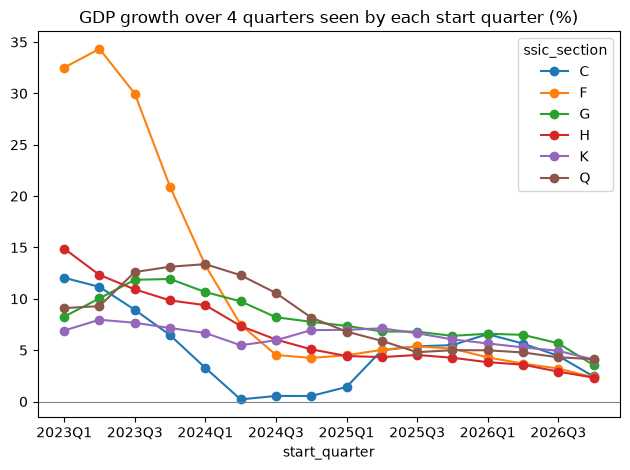

In [5]:
last_q = int(by_section.dropna(how='all').index.max())
rows = []
for start in START_QUARTERS:
    wanted = qnum(start) - GDP_LAG
    used = min(wanted, last_q)
    sum4 = by_section.loc[used - 3:used].sum(min_count=4)
    sum4_before = by_section.loc[used - 7:used - 4].sum(min_count=4)
    rows.append(pd.DataFrame({
        'start_quarter': start, 'ssic_section': by_section.columns, 'gdp_quarter_used': qlabel(used),
        'gdp_gap_quarters': wanted - used,
        'gdp_growth_yoy': (by_section.loc[used] / by_section.loc[used - 4] - 1).to_numpy(),
        'gdp_growth_4q': (sum4 / sum4_before - 1).to_numpy(),
        'gdp_share_4q': (sum4 / total.loc[used - 3:used].sum(min_count=4)).to_numpy()}))
gdp_features = pd.concat(rows, ignore_index=True)

assert (gdp_features['gdp_quarter_used'].map(qnum) < gdp_features['start_quarter'].map(qnum)).all(), 'Leakage: a GDP quarter is not before the start'
print(f'Leakage check passed | newest GDP quarter: {qlabel(last_q)} | rows: {len(gdp_features)}')
print(gdp_features.groupby('start_quarter')[['gdp_quarter_used', 'gdp_gap_quarters']].first().T.to_string())

plot = gdp_features[gdp_features['gdp_gap_quarters'] == 0].pivot(index='start_quarter', columns='ssic_section', values='gdp_growth_4q')
(plot[['C', 'F', 'G', 'H', 'K', 'Q']] * 100).plot(title='GDP growth over 4 quarters seen by each start quarter (%)', marker='o')
plt.axhline(0, color='grey', lw=0.8); plt.tight_layout(); plt.show()

## Part B — SME revenues and expenses (GASTAT, yearly)
The MC files have no size column, and almost every new business is **micro**, so the micro rows are used.
For a business starting in year Y, the year used is **Y − SME_LAG**.

| Feature | Meaning |
|---|---|
| `sme_rev_exp_ratio` | revenues ÷ expenses of micro businesses in the section (above 1 = they earn more than they spend) |
| `sme_revenue_growth` | revenues ÷ revenues the year before − 1 |

In [6]:
sme = pd.read_parquet(RAW / 'gastat' / 'gastat_sme_operating_expenses_revenues_2026-10-21T09_39_24.273Z.csv.parquet')
sme['value'] = pd.to_numeric(sme['Value'], errors='coerce')
sme['year'] = sme['Year'].astype(int)
assert not sme.duplicated(['Economic Sectors ID', 'Establishment Size ID', 'Flow ID', 'Year']).any()
micro = sme[sme['Establishment Size'].str.contains('Micro', case=False)]

def flow(word):
    rows = micro[micro['Flow'].str.contains(word, case=False)]
    return rows.pivot(index='year', columns='Economic Sectors ID', values='value')

revenues, expenses = flow('Revenu'), flow('Expens')
last_year = int(revenues.dropna(how='all').index.max())
rows = []
for start_year in sorted({int(q[:4]) for q in START_QUARTERS}):
    wanted = start_year - SME_LAG
    used = min(wanted, last_year)
    rows.append(pd.DataFrame({
        'start_year': start_year, 'ssic_section': revenues.columns, 'sme_year_used': used, 'sme_gap_years': wanted - used,
        'sme_rev_exp_ratio': (revenues.loc[used] / expenses.loc[used].where(expenses.loc[used] > 0)).to_numpy(),
        'sme_revenue_growth': (revenues.loc[used] / revenues.loc[used - 1].where(revenues.loc[used - 1] > 0) - 1).to_numpy()}))
sme_features = pd.concat(rows, ignore_index=True).replace([np.inf, -np.inf], np.nan)
assert (sme_features['sme_year_used'] < sme_features['start_year']).all(), 'Leakage: an SME year is not before the start'
print(f'Leakage check passed | newest SME year: {last_year} | sections: {sorted(revenues.columns)}')
print('Sections with no SME data:', [s for s in SECTIONS if s not in revenues.columns])
sme_features.pivot(index='ssic_section', columns='start_year', values='sme_rev_exp_ratio').round(2)

Leakage check passed | newest SME year: 2024 | sections: ['B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'P', 'Q', 'R', 'S']
Sections with no SME data: ['A', 'O', 'T', 'U']


start_year,2023,2024,2025,2026,2027
ssic_section,,,,,
B,3.16,3.16,2.52,2.55,2.55
C,2.22,2.26,3.02,3.04,3.04
D,2.84,2.92,2.65,2.69,2.69
E,2.43,2.45,2.11,2.14,2.14
F,1.84,1.88,2.45,2.48,2.48
G,1.66,1.67,1.94,1.98,1.98
H,2.37,2.46,2.50,2.53,2.53
I,1.94,1.97,2.21,2.14,2.14
J,2.43,2.51,2.50,2.40,2.40


## Part C — SAMA point-of-sale spending (weekly)

### C1 — Clean the old series (May 2020 – Jul 2025)
Only the **levels** are kept (number and value of transactions). The `Change %` rows are dropped as an indicator
(they are growth numbers already, and we compute our own). The file has **no city × sector numbers**, so the
sector rows (whole country) and the city rows (all sectors) are two separate tables.

In [7]:
pos = pd.read_parquet(RAW / 'sama' / 'point-of-sale-transactions-by-sector-and-city.xlsx.parquet')
pos.columns = ['week', 'indicator', 'sector', 'city', 'value']
pos['week'] = pd.to_datetime(pos['week'].str[:10])
pos['value'] = pd.to_numeric(pos['value'], errors='coerce')
MEASURE = {'Number of Transactions (In Thousand)': 'count', 'Value of Transactions (In Thousand SAR)': 'value'}
levels = pos[pos['indicator'].isin(MEASURE)].assign(measure=lambda t: t['indicator'].map(MEASURE))
assert (levels['value'] >= 0).all(), 'A negative level'
sector_rows = levels[(levels['city'] == 'Total') & (levels['sector'] != 'Total')]
city_rows = levels[(levels['sector'] == 'Total') & (levels['city'] != 'Total')]
grand_rows = levels[(levels['sector'] == 'Total') & (levels['city'] == 'Total')]
print(f'Weeks: {levels["week"].nunique()} ({levels["week"].min():%Y-%m-%d} to {levels["week"].max():%Y-%m-%d}) | '
      f'sectors: {sector_rows["sector"].nunique()} | cities: {city_rows["city"].nunique()}')
check = sector_rows.groupby(['week', 'measure'])['value'].sum() / grand_rows.set_index(['week', 'measure'])['value']
print(f'Sectors add up to the total: ratio {check.min():.4f} – {check.max():.4f}')

Weeks: 270 (2020-05-10 to 2025-07-06) | sectors: 17 | cities: 11
Sectors add up to the total: ratio 0.9999 – 1.0000


### C2 — SAMA sectors → SSIC (the agreed table) and SAMA cities → MC cities
Same tables as `experiments/05_sama_preprocessing` (M1, M2). A SAMA sector is the **type of shop where people
pay by card**. The 7 shop types SSIC cannot tell apart (all retail, division 47) are added together for a G
business. Miscellaneous and Other are too mixed and are not given to any section. Sections with no SAMA sector
get an empty POS feature.

A business in one of SAMA's 10 named cities gets that city; any other city gets SAMA's **OTHER** row.

In [8]:
SAMA_SECTOR_MAP = [   # (SAMA sector, SSIC section, SSIC division: '' = the whole section)
    ('Beverage and Food', 'G', ''), ('Clothing and Footwear', 'G', ''), ('Electronic & Electric Devices', 'G', ''),
    ('Furniture', 'G', ''), ('Jewelry', 'G', ''), ('Gas Stations', 'G', ''), ('Construction & Building Materials', 'G', ''),
    ('Construction & Building Materials', 'F', ''), ('Hotels', 'I', '55'), ('Restaurants & Café', 'I', '56'),
    ('Education', 'P', ''), ('Health', 'Q', ''), ('Recreation and Culture', 'R', ''), ('Transportation', 'H', ''),
    ('Telecommunication', 'J', ''), ('Public Utilities', 'D', ''), ('Public Utilities', 'E', ''),
    ('Miscellaneous Goods and Services', '', ''), ('Other', '', ''),
]
unknown = set(sector_rows['sector']) - {s for s, _, _ in SAMA_SECTOR_MAP}
assert not unknown, f'SAMA sectors not in the agreed table: {unknown}'
FEEDS = {}                      # (section, division) -> SAMA sectors; a division also feeds its whole section
for sector, section, division in SAMA_SECTOR_MAP:
    if section:
        FEEDS.setdefault((section, ''), []).append(sector)
        if division:
            FEEDS.setdefault((section, division), []).append(sector)
print({f'{s}{d}': v for (s, d), v in FEEDS.items()})

CITY_AR = {'RIYADH': ['الرياض'], 'JEDDAH': ['جدة'], 'MAKKAH': ['مكة المكرمة', 'مكة'], 'MADINA': ['المدينة المنورة', 'المدينة'],
           'DAMMAM': ['الدمام'], 'KHOBAR': ['الخبر'], 'ABHA': ['أبها'], 'BURAIDAH': ['بريدة'], 'TABOUK': ['تبوك'], 'HAIL': ['حائل']}

def normalize_ar(text):
    t = re.sub('[إأآ]', 'ا', str(text)).replace('ة', 'ه').replace('ى', 'ي')
    return re.sub(r'[\u064B-\u0652\u0640]', '', t).strip()

AR_TO_SAMA = {normalize_ar(a): city for city, names in CITY_AR.items() for a in names}
mc_cities = pd.read_parquet(need(PIPE / '02_businesses.parquet', '02_preprocess_businesses'), columns=['city'])['city']
city_to_sama = pd.DataFrame({'city': mc_cities.dropna().astype(str).unique()})
city_to_sama['sama_city'] = city_to_sama['city'].map(normalize_ar).map(AR_TO_SAMA).fillna('OTHER')
city_to_sama.to_csv(PIPE / '03_city_to_sama.csv', index=False, encoding='utf-8-sig')
print(f'\nMC cities: {len(city_to_sama):,} | matched to a named SAMA city: {(city_to_sama["sama_city"] != "OTHER").sum()}')
print(city_to_sama[city_to_sama['sama_city'] != 'OTHER'].groupby('sama_city')['city'].apply(list).to_string())

{'G': ['Beverage and Food', 'Clothing and Footwear', 'Electronic & Electric Devices', 'Furniture', 'Jewelry', 'Gas Stations', 'Construction & Building Materials'], 'F': ['Construction & Building Materials'], 'I': ['Hotels', 'Restaurants & Café'], 'I55': ['Hotels'], 'I56': ['Restaurants & Café'], 'P': ['Education'], 'Q': ['Health'], 'R': ['Recreation and Culture'], 'H': ['Transportation'], 'J': ['Telecommunication'], 'D': ['Public Utilities'], 'E': ['Public Utilities']}



MC cities: 245 | matched to a named SAMA city: 10
sama_city
ABHA                   [ابها]
BURAIDAH              [بريده]
DAMMAM               [الدمام]
HAIL                   [حائل]
JEDDAH                  [جده]
KHOBAR                [الخبر]
MADINA      [المدينه المنوره]
MAKKAH          [مكه المكرمه]
RIYADH               [الرياض]
TABOUK                 [تبوك]


### C3 — POS features per start quarter
For a business starting in quarter Q: the **52 weeks that end before Q starts**. Yearly amount = the average week
× 52. Growth compares those 52 weeks with the 52 before them. A series with fewer than 90% of its weeks gets an
empty value (so start quarters after the old series ends are empty until the new series is mapped, see C4).

| Feature | Meaning |
|---|---|
| `pos_sector_value_year` / `pos_city_value_year` | Yearly card spending in the sector (whole country) / in the city (thousand SAR) |
| `pos_sector_share` / `pos_city_share` | Share of all card spending in the country |
| `pos_sector_avg_ticket` / `pos_city_avg_ticket` | Value ÷ number of transactions = average spend per payment |
| `pos_sector_growth` / `pos_city_growth` | Yearly value ÷ the year before − 1 |

Start quarters with SAMA sector numbers: ['2023Q1', '2023Q2', '2023Q3', '2023Q4', '2024Q1', '2024Q2', '2024Q3', '2024Q4', '2025Q1', '2025Q2', '2025Q3']
start_quarter 2023Q1 2023Q2 2023Q3 2023Q4 2024Q1 2024Q2 2024Q3 2024Q4 2025Q1 2025Q2 2025Q3
ssic_section                                                                              
D               0.8%   0.8%   0.8%   0.9%   0.9%   0.9%   0.8%   0.7%   0.6%   0.5%   0.4%
E               0.8%   0.8%   0.8%   0.9%   0.9%   0.9%   0.8%   0.7%   0.6%   0.5%   0.4%
F               3.4%   3.2%   3.1%   2.9%   2.9%   2.8%   2.7%   2.7%   2.7%   2.6%   2.6%
G              39.9%  39.4%  39.0%  38.6%  38.3%  38.1%  37.9%  37.7%  37.7%  37.5%  37.3%
H               5.5%   5.6%   5.6%   5.7%   5.8%   5.7%   5.7%   5.7%   5.7%   5.7%   5.6%
I              16.3%  16.5%  16.7%  16.8%  17.0%  17.0%  16.9%  16.9%  16.8%  16.6%  16.5%
J               0.9%   0.9%   0.9%   0.8%   0.8%   0.8%   0.8%   0.9%   0.9%   0.9%   0.9%
P               1.5%   1.5%  

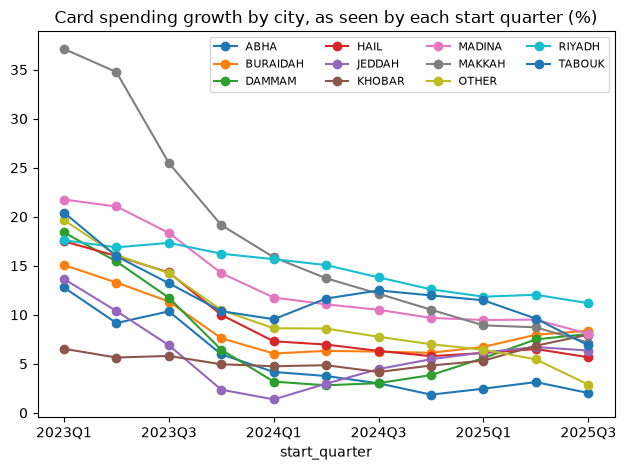

In [9]:
def yearly(rows, key, end):
    """Average week x 52 for the 52 weeks ending before `end` (empty if fewer than 90% of the weeks)."""
    window = rows[(rows['week'] >= end - pd.Timedelta(days=364)) & (rows['week'] + pd.Timedelta(days=6) < end)]
    g = window.groupby([key, 'measure'])['value']
    out = (g.mean() * 52).where(g.count() >= 0.9 * 52)
    return out.unstack('measure').reindex(columns=['count', 'value'])

sector_out, city_out = [], []
for start in START_QUARTERS:
    end = pd.Period(start, 'Q').start_time
    now_s, before_s = yearly(sector_rows, 'sector', end), yearly(sector_rows, 'sector', end - pd.Timedelta(days=364))
    now_c, before_c = yearly(city_rows, 'city', end), yearly(city_rows, 'city', end - pd.Timedelta(days=364))
    national = yearly(grand_rows, 'sector', end)['value'].sum(min_count=1)
    for (section, division), sectors in FEEDS.items():
        value, count = now_s.reindex(sectors)['value'].sum(min_count=len(sectors)), now_s.reindex(sectors)['count'].sum(min_count=len(sectors))
        value_before = before_s.reindex(sectors)['value'].sum(min_count=len(sectors))
        sector_out.append({'start_quarter': start, 'ssic_section': section, 'ssic_division': division,
                           'pos_sector_value_year': value, 'pos_sector_share': value / national,
                           'pos_sector_avg_ticket': value / count if count else np.nan,
                           'pos_sector_growth': value / value_before - 1})
    for city in now_c.index:
        value, count = now_c.loc[city, 'value'], now_c.loc[city, 'count']
        city_out.append({'start_quarter': start, 'sama_city': city, 'pos_city_value_year': value,
                         'pos_city_share': value / national, 'pos_city_avg_ticket': value / count if count else np.nan,
                         'pos_city_growth': value / before_c['value'].get(city, np.nan) - 1})

pos_sector = pd.DataFrame(sector_out).replace([np.inf, -np.inf], np.nan)
pos_city = pd.DataFrame(city_out).replace([np.inf, -np.inf], np.nan)
print('Start quarters with SAMA sector numbers:', sorted(pos_sector.dropna(subset=['pos_sector_value_year'])['start_quarter'].unique()))
print(pos_sector[pos_sector['ssic_division'] == ''].pivot(index='ssic_section', columns='start_quarter', values='pos_sector_share')
      .loc[:, '2023Q1':'2025Q3'].map('{:.1%}'.format).to_string())

(pos_city.pivot(index='start_quarter', columns='sama_city', values='pos_city_growth').loc['2023Q1':'2025Q3'] * 100).plot(
    title='Card spending growth by city, as seen by each start quarter (%)', marker='o')
plt.legend(ncol=4, fontsize=8); plt.tight_layout(); plt.show()

### C4 — The new SAMA series (Jun 2025 – Nov 2026): waiting for its mapping
In mid-2025 SAMA changed its lists: 17 sectors → 19 sectors + 9 sub-sectors, and 10 cities + OTHER → 60 cities +
Others. The old mapping does not fit them, so **founders starting from 2025 Q4 have no SAMA features yet**.
Training is not affected: every training cohort starts by 2025 Q3, inside the old series.

**To do (needs the team's OK):** write `NEW_SAMA_SECTOR_MAP` and the new city table below, then build these
features from the new series the same way as C3. Here the new lists are only printed.

In [10]:
new = pd.read_parquet(RAW / 'sama' / 'sama_pos_weekly_2025-06_to_2026-11.csv.parquet')
print('New sector list:', sorted(new.loc[new['level'] == 'sector', 'name'].unique()))
print('\nNew sub-sectors:', sorted((new.loc[new['level'] == 'sub_sector', 'parent_sector'] + ' / ' + new.loc[new['level'] == 'sub_sector', 'name']).unique()))
print(f'\nNew cities: {new.loc[new["level"] == "city", "name"].nunique()}')
NEW_SAMA_SECTOR_MAP = None     # waiting for the team's OK

New sector list: ['Airlines', 'Apparel, Clothing & Accessories', 'Auto & Equipment Rentals', 'Bakeries & Pastries', 'Books & Stationery', 'Construction & Building Materials', 'Education', 'Electronic & Electric Devices', 'Food & Beverages', 'Freight Transport & Postal & Courier Services', 'Furniture & Home Supplies', 'Gas Stations', 'Health', 'Hotels', 'Jewelry', 'Laundry Services', 'Maintenance & Repair of Vehicles', 'Medical Services', 'Others', 'Others (Transportation)', 'Personal Care', 'Pharmacies & Medical Supplies', 'Professional & Business Services', 'Public Utilities & Services', 'Recreation', 'Recreation & Culture', 'Restaurants & Café', 'Telecommunication', 'Total', 'Trade of Vehicles & Spare Parts', 'Transportation']

New sub-sectors: []

New cities: 61


## Part D — Licensing (SSIC file)
For each SSIC division and section: how many activities it has, and the share that needs a licence from an
authority **other than** the Ministry of Commerce (e.g. health, municipality). An activity that needs another
licence is harder to start. These are facts about the activity, not about time, so there is no leakage.

In [11]:
raw = pd.read_parquet(RAW / 'gastat' / 'National Classification for the Economic Activities(SSIC)_15 Sep_2026_AR.xlsx.parquet')
header_row = raw.index[raw['0'].fillna('').str.strip() == 'رمز الباب'][0]
ssic = raw.iloc[header_row + 1:].copy()
ssic.columns = ['section_code', 'section_name', 'division_code', 'division_name', 'group_code', 'group_name', 'class_code',
                'class_name', 'activity_code', 'activity_name', 'activity_description', 'supervising_authority', 'licensing_authority']
ssic = ssic.apply(lambda c: c.str.strip())
levels_cols = ['section_code', 'section_name', 'division_code', 'division_name']
ssic[levels_cols] = ssic[levels_cols].ffill()
ssic = ssic.dropna(subset=['activity_code'])
ssic['division_code'] = ssic['division_code'].str.replace(r'\.0$', '', regex=True).str.zfill(2)

ARABIC_TO_LATIN = {'ا': 'A', 'ب': 'B', 'ج': 'C', 'د': 'D', 'ه': 'E', 'و': 'F', 'ز': 'G', 'ح': 'H', 'ط': 'I', 'ي': 'J', 'ك': 'K',
                   'ل': 'L', 'م': 'M', 'ن': 'N', 'س': 'O', 'ع': 'P', 'ف': 'Q', 'ص': 'R', 'ق': 'S', 'ر': 'T', 'ش': 'U'}
letter = ssic['section_code'].str.replace(r'[ـ\s]', '', regex=True).str.replace('[أإآ]', 'ا', regex=True).str.replace('ى', 'ي')
ssic['ssic_section'] = letter.map(ARABIC_TO_LATIN)
assert ssic['ssic_section'].notna().all(), 'A section code is not in ARABIC_TO_LATIN'
KNOWN = {'01': 'A', '10': 'C', '41': 'F', '47': 'G', '56': 'I', '62': 'J', '86': 'Q'}
found = ssic.drop_duplicates('division_code').set_index('division_code')['ssic_section']
assert all(found[d] == s for d, s in KNOWN.items()), 'Divisions in the wrong section: check ARABIC_TO_LATIN'

licensing_text = ssic['licensing_authority'].fillna('').str.replace(r'\s+', ' ', regex=True)
rest = licensing_text.str.replace(r'وزار[ةه] التجار[ةه]( والاستثمار)?', '', regex=True).str.replace(r'[،,;/\-–()و]', ' ', regex=True).str.strip()
ssic['licensed_outside_mc'] = (licensing_text != '') & (rest.str.len() > 2)

by_division = ssic.groupby(['ssic_section', 'division_code']).agg(
    n_activities=('activity_code', 'size'), licensed_outside_mc_share=('licensed_outside_mc', 'mean')).reset_index()
by_division = by_division.rename(columns={'division_code': 'ssic_division'})
by_section = ssic.groupby('ssic_section').agg(n_activities=('activity_code', 'size'),
                                              licensed_outside_mc_share=('licensed_outside_mc', 'mean')).reset_index()
licensing = pd.concat([by_division, by_section.assign(ssic_division='')], ignore_index=True)
sections = ssic.drop_duplicates('ssic_section')[['ssic_section', 'section_name']].sort_values('ssic_section')
print(f'{len(ssic):,} activities | licensed outside MC: {ssic["licensed_outside_mc"].mean():.1%}')
print(by_section.merge(sections).to_string(index=False, formatters={'licensed_outside_mc_share': '{:.0%}'.format}))

2,847 activities | licensed outside MC: 94.1%
ssic_section  n_activities licensed_outside_mc_share                                                         section_name
           A            79                      100%                                        الزراعة والحراجة وصيد الأسماك
           B            23                      100%                                             التعدين واستغلال المحاجر
           C          1262                      100%                                                    الصناعة التحويلية
           D            15                      100%                        إمدادات الكهرباء والغاز والبخار وتكييف الهواء
           E            47                      100%          إمدادات المياه وأنشطة الصرف الصحي وإدارة النفايات ومعالجتها
           F           101                      100%                                                              التشييد
           G           458                       70% تجارة الجملة والتجزئة وإصلاح المركبات ذات المحر

## Save

In [12]:
gdp_features.to_parquet(PIPE / '03_gdp_features.parquet', index=False)
sme_features.to_parquet(PIPE / '03_sme_features.parquet', index=False)
pos_sector.to_parquet(PIPE / '03_sama_sector_features.parquet', index=False)
pos_city.to_parquet(PIPE / '03_sama_city_features.parquet', index=False)
licensing.to_parquet(PIPE / '03_licensing.parquet', index=False)
sections.to_csv(PIPE / '03_ssic_sections.csv', index=False, encoding='utf-8-sig')
for name in ['03_gdp_features.parquet', '03_sme_features.parquet', '03_sama_sector_features.parquet',
             '03_sama_city_features.parquet', '03_licensing.parquet', '03_city_to_sama.csv', '03_ssic_sections.csv']:
    print('Saved', PIPE / name)

Saved /Users/halaalsabbar/darb-data/pipeline/03_gdp_features.parquet
Saved /Users/halaalsabbar/darb-data/pipeline/03_sme_features.parquet
Saved /Users/halaalsabbar/darb-data/pipeline/03_sama_sector_features.parquet
Saved /Users/halaalsabbar/darb-data/pipeline/03_sama_city_features.parquet
Saved /Users/halaalsabbar/darb-data/pipeline/03_licensing.parquet
Saved /Users/halaalsabbar/darb-data/pipeline/03_city_to_sama.csv
Saved /Users/halaalsabbar/darb-data/pipeline/03_ssic_sections.csv
